<a href="https://colab.research.google.com/github/Martin-Emenezi/martin-emenezi-data-analytics-portfolio/blob/main/01-battery-health-analytics/01_Battery_Health_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Notebook introduction


# NASA Lithium-Ion Battery Health Analysis
## Notebook 1: download, load, and inspect

This beginner workflow downloads NASA's Battery Data Set, selects the FY08Q4 archive containing batteries B0005, B0006, B0007, and B0018, loads the MATLAB `.mat` files, and inspects their nested structure. It does not make an analysis table or train a model yet.

Run the cells from top to bottom. The archive is tens of megabytes and may take a few minutes.

## Dataset provenance

- **Dataset:** NASA PCoE Battery Data Set (Saha and Goebel, 2007).
- **NASA repository and download instructions:** https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/
- **Archive linked by NASA:** https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip
- **NASA catalog and field description:** https://catalog.data.gov/dataset/li-ion-battery-aging-datasets
- **Selected files:** `B0005.mat`, `B0006.mat`, `B0007.mat`, and `B0018.mat` from FY08Q4.
- **Format:** MATLAB structures. Each battery contains a `cycle` array. Each cycle has `type`, `ambient_temperature`, start `time`, and nested `data`; measurement fields differ by charge, discharge, and impedance operation.
- **Citation:** B. Saha and K. Goebel (2007). "Battery Data Set", NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA.

NASA's Open Data catalog marks the data public and lists its license as "License not specified." Keep the source and citation with any results.

## 1. Set up the reader and folders

Colab usually has SciPy already. The install cell confirms it is available. Files in `/content` are temporary and must be downloaded again after a runtime reset.

In [1]:
# @title
%pip -q install scipy
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from collections import Counter
from datetime import date
import requests
import numpy as np
from scipy.io import loadmat

DATASET_URL = "https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip"
ARCHIVE_PATH = Path("/content/nasa_battery_data.zip")
DATA_DIR = Path("/content/nasa_battery_data/FY08Q4")
BATTERIES = ["B0005", "B0006", "B0007", "B0018"]
DATA_DIR.mkdir(parents=True, exist_ok=True)
print("Data folder:", DATA_DIR)

Data folder: /content/nasa_battery_data/FY08Q4


## 2. Download the NASA archive

The NASA repository links the URL below. The outer ZIP contains multiple packages; the next cell finds FY08Q4 and extracts only the files needed here.

In [2]:
# @title
if not ARCHIVE_PATH.exists():
    response = requests.get(DATASET_URL, stream=True, timeout=(20, 120))
    response.raise_for_status()
    size = 0
    with ARCHIVE_PATH.open("wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)
                size += len(chunk)
    print(f"Downloaded {size / (1024 * 1024):.1f} MB to {ARCHIVE_PATH}")
else:
    print("Archive already exists:", ARCHIVE_PATH)

if not ARCHIVE_PATH.exists() or ARCHIVE_PATH.stat().st_size == 0:
    raise FileNotFoundError("NASA ZIP was not downloaded. Check the URL and try again.")

# Optional fallback if automatic download fails:
# from google.colab import files
# uploaded = files.upload()  # select the NASA ZIP downloaded in your browser
# ARCHIVE_PATH = Path("/content") / next(iter(uploaded))

Downloaded 200.0 MB to /content/nasa_battery_data.zip


## 3. Find FY08Q4 and extract the battery files

This inspects the archive and extracts the four `.mat` files plus the package's `README.txt`.

In [3]:
# @title
with ZipFile(ARCHIVE_PATH) as outer_zip:
    candidates = [n for n in outer_zip.namelist()
                  if "FY08Q4" in n.upper() and n.lower().endswith(".zip")]
    print("FY08Q4 archive candidates:", candidates)
    if not candidates:
        raise FileNotFoundError("No FY08Q4 ZIP found inside the NASA archive.")
    nested_bytes = outer_zip.read(candidates[0])

wanted = {f"{b}.mat" for b in BATTERIES} | {"README.txt"}
with ZipFile(BytesIO(nested_bytes)) as fy08q4_zip:
    print("FY08Q4 package contents:")
    for name in fy08q4_zip.namelist():
        print(" -", name)
    extracted = []
    for name in fy08q4_zip.namelist():
        basename = Path(name).name
        if basename in wanted:
            (DATA_DIR / basename).write_bytes(fy08q4_zip.read(name))
            extracted.append(basename)

missing = sorted({f"{b}.mat" for b in BATTERIES} - set(extracted))
if missing:
    raise FileNotFoundError(f"Expected battery file(s) missing: {missing}")
print("Extracted:", sorted(extracted))

FY08Q4 archive candidates: ['5. Battery Data Set/1. BatteryAgingARC-FY08Q4.zip']
FY08Q4 package contents:
 - B0007.mat
 - B0018.mat
 - README.txt
 - B0005.mat
 - B0006.mat
Extracted: ['B0005.mat', 'B0006.mat', 'B0007.mat', 'B0018.mat', 'README.txt']


## 4. Check files and load the MATLAB structures

In [4]:
# @title
for path in sorted(DATA_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name:12} {path.stat().st_size / (1024 * 1024):8.2f} MB")

loaded = {}
for battery in BATTERIES:
    mat = loadmat(DATA_DIR / f"{battery}.mat", squeeze_me=True, struct_as_record=False)
    keys = [k for k in mat if not k.startswith("__")]
    if battery not in mat:
        raise KeyError(f"Expected top-level key {battery!r}; found {keys}")
    loaded[battery] = mat[battery]
    print(f"{battery} top-level MATLAB key: {battery}")

def get_field(obj, name):
    return obj[name] if isinstance(obj, dict) else getattr(obj, name)

def field_names(obj):
    return list(getattr(obj, "_fieldnames", []) or [])

def as_text(value):
    if isinstance(value, bytes):
        return value.decode("utf-8", errors="replace").strip()
    if isinstance(value, np.ndarray):
        flat = value.reshape(-1)
        if value.dtype.kind in {"U", "S", "O"} and all(
            isinstance(x, (str, bytes, np.str_, np.bytes_)) for x in flat
        ):
            return "".join(as_text(x) for x in flat).strip()
        if value.size == 1:
            return as_text(value.item())
    return str(value).strip()

def cycles_for(obj):
    return list(np.asarray(get_field(obj, "cycle"), dtype=object).reshape(-1))

for battery in BATTERIES:
    cycles = cycles_for(loaded[battery])
    counts = Counter(as_text(get_field(c, "type")).lower() for c in cycles)
    print(f"{battery}: {len(cycles)} records; operation counts = {dict(counts)}")

B0005.mat       15.22 MB
B0006.mat       15.29 MB
B0007.mat       15.31 MB
B0018.mat        8.11 MB
README.txt       0.00 MB
B0005 top-level MATLAB key: B0005
B0006 top-level MATLAB key: B0006
B0007 top-level MATLAB key: B0007
B0018 top-level MATLAB key: B0018
B0005: 616 records; operation counts = {'charge': 170, 'discharge': 168, 'impedance': 278}
B0006: 616 records; operation counts = {'charge': 170, 'discharge': 168, 'impedance': 278}
B0007: 616 records; operation counts = {'charge': 170, 'discharge': 168, 'impedance': 278}
B0018: 319 records; operation counts = {'charge': 134, 'impedance': 53, 'discharge': 132}


## 5. Inspect B0005's nested fields and sample values

The raw files are not flat tables. The `cycle` array contains charge, discharge, or impedance records, and the measurement fields inside `data` vary by operation. NASA's documentation lists voltage, current, temperature, and elapsed time for charge/discharge; discharge also has `Capacity` in ampere-hours. Impedance records include fields such as `Battery_impedance`, `Re`, and `Rct`.

In [5]:
# @title
cycles = cycles_for(loaded["B0005"])
print("Battery fields:", field_names(loaded["B0005"]))
print("Cycle record fields:", field_names(cycles[0]))

samples = {}
for cycle in cycles:
    operation = as_text(get_field(cycle, "type")).lower()
    samples.setdefault(operation, cycle)

for operation in ["charge", "discharge", "impedance"]:
    sample = samples.get(operation)
    if sample is None:
        print(f"\nNo {operation} sample found")
        continue
    data = get_field(sample, "data")
    print(f"\n{operation.upper()} fields:", field_names(data))
    for field in field_names(data):
        values = np.asarray(get_field(data, field))
        print(f"  {field}: shape={values.shape}, dtype={values.dtype}, first values={values.reshape(-1)[:3].tolist()}")

Battery fields: ['cycle']
Cycle record fields: ['type', 'ambient_temperature', 'time', 'data']

CHARGE fields: ['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_charge', 'Voltage_charge', 'Time']
  Voltage_measured: shape=(789,), dtype=float64, first values=[3.873017221300996, 3.479393559379272, 4.000587822429767]
  Current_measured: shape=(789,), dtype=float64, first values=[-0.001200660698297908, -4.030268477538787, 1.5127306474745377]
  Temperature_measured: shape=(789,), dtype=float64, first values=[24.65535783391511, 24.66647981177477, 24.675394470060205]
  Current_charge: shape=(789,), dtype=float64, first values=[0.0, -4.036, 1.5]
  Voltage_charge: shape=(789,), dtype=float64, first values=[0.003, 1.57, 4.726]
  Time: shape=(789,), dtype=float64, first values=[0.0, 2.532, 5.5]

DISCHARGE fields: ['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity']
  Voltage_measured: shape=(197,), dtype=float

## 6. Save a provenance note next to the extracted data

In [6]:
# @title
provenance = f"""# Dataset provenance

- Dataset: NASA PCoE Battery Data Set (Saha and Goebel, 2007)
- Official NASA repository: https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/
- Official archive URL: {DATASET_URL}
- NASA catalog and field description: https://catalog.data.gov/dataset/li-ion-battery-aging-datasets
- Package selected: FY08Q4
- Files selected: {", ".join(f"{b}.mat" for b in BATTERIES)}
- Access date: {date.today().isoformat()} (Colab runtime date)
- Format: MATLAB .mat; nested cycle records for charge, discharge, and impedance
- Citation: B. Saha and K. Goebel (2007). "Battery Data Set", NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA.
- NASA Open Data catalog license field: License not specified.
"""
provenance_path = DATA_DIR / "PROVENANCE.md"
provenance_path.write_text(provenance, encoding="utf-8")
print(provenance)
print("Saved:", provenance_path)

# Dataset provenance

- Dataset: NASA PCoE Battery Data Set (Saha and Goebel, 2007)
- Official NASA repository: https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/
- Official archive URL: https://phm-datasets.s3.amazonaws.com/NASA/5.+Battery+Data+Set.zip
- NASA catalog and field description: https://catalog.data.gov/dataset/li-ion-battery-aging-datasets
- Package selected: FY08Q4
- Files selected: B0005.mat, B0006.mat, B0007.mat, B0018.mat
- Access date: 2026-11-14 (Colab runtime date)
- Format: MATLAB .mat; nested cycle records for charge, discharge, and impedance
- Citation: B. Saha and K. Goebel (2007). "Battery Data Set", NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA.
- NASA Open Data catalog license field: License not specified.

Saved: /content/nasa_battery_data/FY08Q4/PROVENANCE.md


## Next checkpoint

You should now see the four source files, operation counts, examples of nested fields, and a `PROVENANCE.md` note. The next notebook can extract one row per discharge cycle and plot measured capacity fade.

Save the notebook into the project folder. Do not commit the raw `.mat` files or ZIP archive to GitHub.

##Sample Discharge-Cycle Measurements

In [8]:
# @title
import pandas as pd
import numpy as np

def numeric_values(obj, field):
    if field not in field_names(obj):
        return np.array([], dtype=float)
    try:
        values = np.asarray(get_field(obj, field), dtype=float).reshape(-1)
        return values[np.isfinite(values)]
    except (TypeError, ValueError):
        return np.array([], dtype=float)

def first_or_nan(values):
    return float(values[0]) if len(values) else np.nan

def max_or_nan(values):
    return float(np.max(values)) if len(values) else np.nan

rows = []

for battery in BATTERIES:
    discharge_number = 0

    for record_index, cycle in enumerate(cycles_for(loaded[battery])):
        operation = as_text(get_field(cycle, "type")).lower()
        if operation != "discharge":
            continue

        discharge_number += 1
        data = get_field(cycle, "data")

        times = numeric_values(data, "Time")
        temperatures = numeric_values(data, "Temperature_measured")
        voltages = numeric_values(data, "Voltage_measured")
        capacities = numeric_values(data, "Capacity")

        rows.append({
            "battery": battery,
            "discharge_number": discharge_number,
            "record_index": record_index,
            "ambient_temperature_c": float(
                np.asarray(get_field(cycle, "ambient_temperature")).reshape(-1)[0]
            ),
            "capacity_ah": first_or_nan(capacities),
            "duration_s": float(np.max(times) - np.min(times)) if len(times) else np.nan,
            "max_temperature_c": max_or_nan(temperatures),
            "start_voltage_v": first_or_nan(voltages),
            "end_voltage_v": float(voltages[-1]) if len(voltages) else np.nan,
        })

discharge_table = pd.DataFrame(rows)

print("Table shape (rows, columns):", discharge_table.shape)
display(discharge_table.head(10))
display(discharge_table.isna().sum().rename("missing values"))

Table shape (rows, columns): (636, 9)


,battery,discharge_number,record_index,ambient_temperature_c,capacity_ah,duration_s,max_temperature_c,start_voltage_v,end_voltage_v
0,B0005,1,1,24.0,1.856487,3690.234,38.982181,4.191492,3.277170
1,B0005,2,3,24.0,1.846327,3672.344,39.033398,4.189773,3.300245
2,B0005,3,5,24.0,1.835349,3651.641,38.818797,4.188187,3.327451
3,B0005,4,7,24.0,1.835263,3631.563,38.762305,4.188461,3.314182
4,B0005,5,9,24.0,1.834646,3629.172,38.665393,4.188299,3.305497
5,B0005,6,11,24.0,1.835662,3652.281,38.751695,4.188816,3.302329
6,B0005,7,13,24.0,1.835146,3650.828,38.820701,4.188392,3.293741
7,B0005,8,15,24.0,1.825757,3572.453,38.517130,4.188928,3.316231
8,B0005,9,17,24.0,1.824774,3550.594,38.526268,4.189029,3.297411
9,B0005,10,19,24.0,1.824613,3551.250,38.526981,4.189223,3.288404


,missing values
battery,0
discharge_number,0
record_index,0
ambient_temperature_c,0
capacity_ah,0
duration_s,0
max_temperature_c,0
start_voltage_v,0
end_voltage_v,0


##	Discharge-Cycle, Capacity, and Temperature Summary

In [9]:
# @title
ordered = discharge_table.sort_values(["battery", "discharge_number"])

battery_summary = (
    ordered.groupby("battery")
    .agg(
        discharge_cycles=("discharge_number", "count"),
        first_capacity_ah=("capacity_ah", "first"),
        last_capacity_ah=("capacity_ah", "last"),
        peak_temperature_c=("max_temperature_c", "max"),
        missing_capacity_values=("capacity_ah", lambda values: values.isna().sum()),
    )
    .reset_index()
)

battery_summary["capacity_change_from_first_pct"] = (
    100
    * (battery_summary["last_capacity_ah"] - battery_summary["first_capacity_ah"])
    / battery_summary["first_capacity_ah"]
)

display(battery_summary)

,battery,discharge_cycles,first_capacity_ah,last_capacity_ah,peak_temperature_c,missing_capacity_values,capacity_change_from_first_pct
0,B0005,168,1.856487,1.325079,41.450232,0,-28.624384
1,B0006,168,2.035338,1.185675,42.007540,0,-41.745525
2,B0007,168,1.891052,1.432455,42.332522,0,-24.250891
3,B0018,132,1.855005,1.341051,38.878688,0,-27.706298


##Measured Discharge Capacity by Battery and Cycle

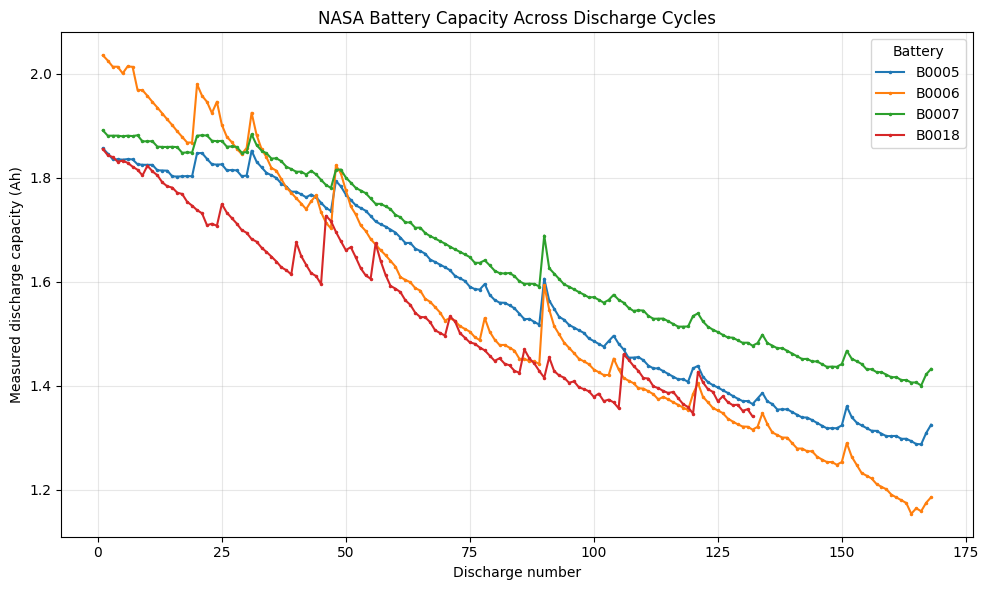

In [10]:
# @title
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for battery, group in discharge_table.groupby("battery"):
    group = group.sort_values("discharge_number")
    plt.plot(
        group["discharge_number"],
        group["capacity_ah"],
        marker=".",
        markersize=3,
        linewidth=1.5,
        label=battery,
    )

plt.xlabel("Discharge number")
plt.ylabel("Measured discharge capacity (Ah)")
plt.title("NASA Battery Capacity Across Discharge Cycles")
plt.legend(title="Battery")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Median Discharge Current Magnitude by Battery (First Discharge)

In [11]:
# @title
current_rows = []

for battery in BATTERIES:
    first_discharge = next(
        cycle for cycle in cycles_for(loaded[battery])
        if as_text(get_field(cycle, "type")).lower() == "discharge"
    )

    data = get_field(first_discharge, "data")
    current = np.asarray(
        get_field(data, "Current_measured"), dtype=float
    ).reshape(-1)
    current = current[np.isfinite(current)]

    current_rows.append({
        "battery": battery,
        "median_current_magnitude_a": float(np.median(np.abs(current))),
    })

display(pd.DataFrame(current_rows))

,battery,median_current_magnitude_a
0,B0005,2.012427
1,B0006,2.010775
2,B0007,1.990024
3,B0018,2.008959


##Peak Measured Battery Temperature and Corresponding Discharge Cycle

In [12]:
# @title
peak_rows = discharge_table.loc[
    discharge_table.groupby("battery")["max_temperature_c"].idxmax(),
    ["battery", "discharge_number", "ambient_temperature_c", "max_temperature_c"],
].sort_values("battery")

display(peak_rows)

,battery,discharge_number,ambient_temperature_c,max_temperature_c
138,B0005,139,24.0,41.450232
286,B0006,119,24.0,42.007540
454,B0007,119,24.0,42.332522
617,B0018,114,24.0,38.878688


## Compare Discharge Capacity Retention Across Batteries

,battery,discharge_cycles,last_capacity_pct,fade_from_first_pct
0,B0005,168,71.375616,28.624384
1,B0006,168,58.254475,41.745525
2,B0007,168,75.749109,24.250891
3,B0018,132,72.293702,27.706298


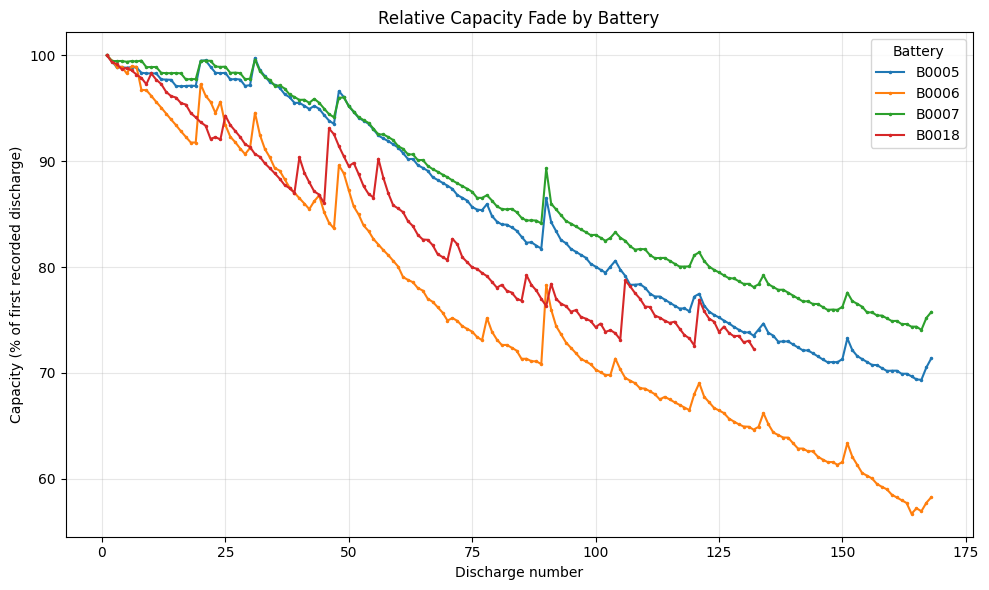

In [13]:
# @title
import matplotlib.pyplot as plt

relative_df = discharge_table.sort_values(
    ["battery", "discharge_number"]
).copy()

first_capacity = relative_df.groupby("battery")["capacity_ah"].transform("first")
relative_df["capacity_pct_of_first"] = (
    100 * relative_df["capacity_ah"] / first_capacity
)

relative_summary = (
    relative_df.groupby("battery")
    .agg(
        discharge_cycles=("discharge_number", "count"),
        last_capacity_pct=("capacity_pct_of_first", "last"),
    )
    .reset_index()
)
relative_summary["fade_from_first_pct"] = (
    100 - relative_summary["last_capacity_pct"]
)

display(relative_summary)

fig, ax = plt.subplots(figsize=(10, 6))

for battery, group in relative_df.groupby("battery"):
    group = group.sort_values("discharge_number")
    ax.plot(
        group["discharge_number"],
        group["capacity_pct_of_first"],
        marker=".",
        markersize=3,
        linewidth=1.5,
        label=battery,
    )

ax.set_xlabel("Discharge number")
ax.set_ylabel("Capacity (% of first recorded discharge)")
ax.set_title("Relative Capacity Fade by Battery")
ax.legend(title="Battery")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Table of X and Y Values for Capacity Retention

In [14]:
# @title
axis_table = (
    relative_df.pivot(
        index="discharge_number",
        columns="battery",
        values="capacity_pct_of_first",
    )
    .reset_index()
    .rename(columns={"discharge_number": "x_discharge_number"})
)

axis_table.columns.name = None
display(axis_table)

,x_discharge_number,B0005,B0006,B0007,B0018
0,1,100.000000,100.000000,100.000000,100.000000
1,2,99.452721,99.498985,99.449234,99.363398
2,3,98.861386,98.918547,99.450590,99.169669
3,4,98.856718,98.916498,99.456314,98.688364
4,5,98.823482,98.289755,99.386510,98.797614
...,...,...,...,...,...
163,164,69.672630,56.689285,74.359204,NaN
164,165,69.378514,57.209230,74.367898,NaN
165,166,69.348842,56.933921,74.056928,NaN
166,167,70.510328,57.728747,75.184938,NaN


## Initial Capacity Retention Findings

Capacity declined overall across the observed discharge cycles, with some cycle-to-cycle fluctuations. Relative to each battery's first recorded discharge, B0006 had the largest capacity fade (41.75%), followed by B0005 (28.62%), B0018 (27.71%), and B0007 (24.25%). B0018 had 132 discharge records; the other batteries had 168.

These percentages compare each battery with its own first recorded capacity. They are exploratory measures, not formal State of Health estimates. The batteries also had different discharge cut-off voltages, so their results should be interpreted with that test-condition difference in mind.

## Track Peak Battery Temperature Across Discharge Cycles

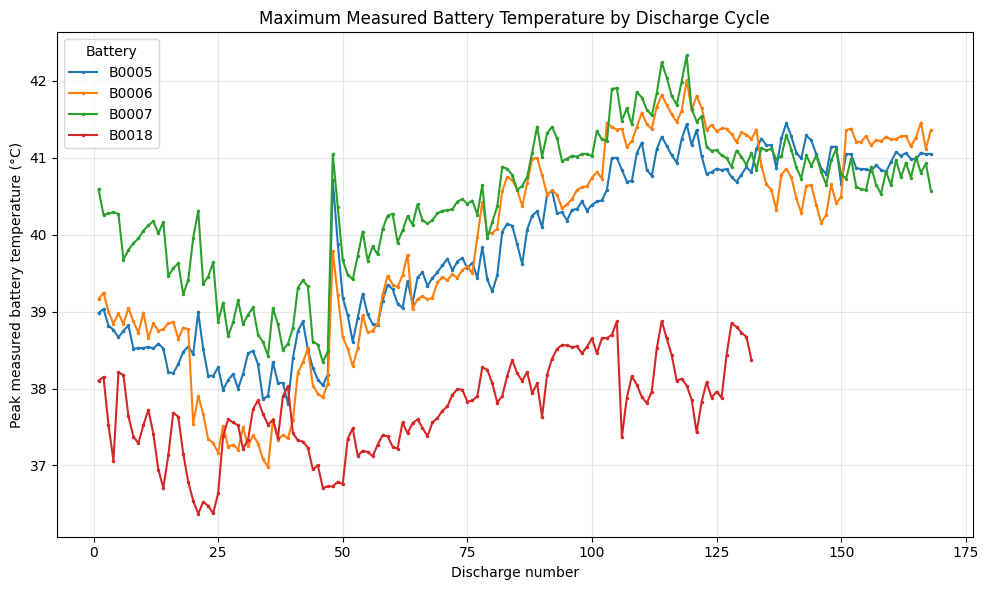

In [15]:
# @title
temperature_data = discharge_table.sort_values(
    ["battery", "discharge_number"]
)

fig, ax = plt.subplots(figsize=(10, 6))

for battery, group in temperature_data.groupby("battery"):
    ax.plot(
        group["discharge_number"],
        group["max_temperature_c"],
        marker=".",
        markersize=3,
        linewidth=1.5,
        label=battery,
    )

ax.set_xlabel("Discharge number")
ax.set_ylabel("Peak measured battery temperature (°C)")
ax.set_title("Maximum Measured Battery Temperature by Discharge Cycle")
ax.legend(title="Battery")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Check Dataset Calendar Span and Discharge Duration

In [16]:
# @title
from datetime import datetime, timedelta
from IPython.display import display, Markdown

def matlab_time_to_datetime(value):
    parts = np.asarray(value, dtype=float).reshape(-1)
    year, month, day, hour, minute = map(int, parts[:5])
    return datetime(year, month, day, hour, minute) + timedelta(
        seconds=float(parts[5])
    )

timing_rows = []

for battery in BATTERIES:
    discharge_number = 0

    for cycle in cycles_for(loaded[battery]):
        if as_text(get_field(cycle, "type")).lower() != "discharge":
            continue

        discharge_number += 1
        timing_rows.append({
            "battery": battery,
            "discharge_number": discharge_number,
            "start_time": matlab_time_to_datetime(
                get_field(cycle, "time")
            ),
        })

timing_df = pd.DataFrame(timing_rows)

calendar_summary = (
    timing_df.groupby("battery")
    .agg(
        first_discharge_start=("start_time", "min"),
        last_discharge_start=("start_time", "max"),
        discharge_cycles=("discharge_number", "count"),
    )
    .reset_index()
)

calendar_summary["calendar_span_days"] = (
    calendar_summary["last_discharge_start"]
    - calendar_summary["first_discharge_start"]
).dt.total_seconds() / 86400

duration_summary = (
    discharge_table.groupby("battery")
    .agg(
        median_duration_min=("duration_s", lambda values: values.median() / 60),
        shortest_duration_min=("duration_s", lambda values: values.min() / 60),
        longest_duration_min=("duration_s", lambda values: values.max() / 60),
    )
    .reset_index()
)

display(Markdown("### Calendar span of discharge records"))
display(calendar_summary)

display(Markdown("### Duration of discharge operations"))
display(duration_summary)

### Calendar span of discharge records

,battery,first_discharge_start,last_discharge_start,discharge_cycles,calendar_span_days
0,B0005,2008-04-02 15:25:41.593,2008-05-27 20:45:42.125,168,55.222228
1,B0006,2008-04-02 15:25:41.593,2008-05-27 20:45:42.125,168,55.222228
2,B0007,2008-04-02 15:25:41.593,2008-05-27 20:45:42.125,168,55.222228
3,B0018,2008-07-07 15:15:28.875,2008-08-20 08:37:19.515,132,43.723503


### Duration of discharge operations

,battery,median_duration_min,shortest_duration_min,longest_duration_min
0,B0005,51.434633,46.541417,61.503900
1,B0006,51.434633,46.541417,61.503900
2,B0007,51.434633,46.541417,61.503900
3,B0018,50.797917,45.714050,57.248183


## Index All Operation Records in the Four-Battery Dataset

In [17]:
# @title
from datetime import datetime, timedelta

def matlab_start_time(value):
    parts = np.asarray(value, dtype=float).reshape(-1)
    year, month, day, hour, minute = map(int, parts[:5])
    return datetime(year, month, day, hour, minute) + timedelta(
        seconds=float(parts[5])
    )

operation_rows = []

for battery in BATTERIES:
    type_counts = {}

    for record_number, cycle in enumerate(cycles_for(loaded[battery]), start=1):
        operation_type = as_text(get_field(cycle, "type")).lower()
        type_counts[operation_type] = type_counts.get(operation_type, 0) + 1

        data = get_field(cycle, "data")
        fields = field_names(data)
        lengths = [
            np.asarray(get_field(data, field)).size
            for field in fields
        ]

        capacity = np.nan
        if "Capacity" in fields:
            capacity_values = np.asarray(
                get_field(data, "Capacity"), dtype=float
            ).reshape(-1)
            if capacity_values.size:
                capacity = float(capacity_values[0])

        operation_rows.append({
            "battery": battery,
            "record_number": record_number,
            "operation_type": operation_type,
            "number_within_type": type_counts[operation_type],
            "ambient_temperature_c": float(
                np.asarray(
                    get_field(cycle, "ambient_temperature"), dtype=float
                ).reshape(-1)[0]
            ),
            "start_time": matlab_start_time(get_field(cycle, "time")),
            "measurement_count": max(lengths, default=0),
            "capacity_ah": capacity,
            "measurement_fields": ", ".join(fields),
        })

operation_table = pd.DataFrame(operation_rows)

print("Operation records:", len(operation_table))
print("Headers:", operation_table.columns.tolist())
display(operation_table.head(25))

operation_table.to_csv(
    "/content/nasa_four_batteries_operation_records.csv",
    index=False,
)
print("Saved the complete operation index as a CSV in Colab.")

Operation records: 2167
Headers: ['battery', 'record_number', 'operation_type', 'number_within_type', 'ambient_temperature_c', 'start_time', 'measurement_count', 'capacity_ah', 'measurement_fields']


,battery,record_number,operation_type,number_within_type,ambient_temperature_c,start_time,measurement_count,capacity_ah,measurement_fields
0,B0005,1,charge,1,24.0,2008-04-02 13:08:17.921,789,NaN,"Voltage_measured, Current_measured, Temperatur..."
1,B0005,2,discharge,1,24.0,2008-04-02 15:25:41.593,197,1.856487,"Voltage_measured, Current_measured, Temperatur..."
2,B0005,3,charge,2,24.0,2008-04-02 16:37:51.984,940,NaN,"Voltage_measured, Current_measured, Temperatur..."
3,B0005,4,discharge,2,24.0,2008-04-02 19:43:48.406,196,1.846327,"Voltage_measured, Current_measured, Temperatur..."
4,B0005,5,charge,3,24.0,2008-04-02 20:55:40.812,937,NaN,"Voltage_measured, Current_measured, Temperatur..."
5,B0005,6,discharge,3,24.0,2008-04-03 00:01:06.687,195,1.835349,"Voltage_measured, Current_measured, Temperatur..."
6,B0005,7,charge,4,24.0,2008-04-03 01:12:38.671,933,NaN,"Voltage_measured, Current_measured, Temperatur..."
7,B0005,8,discharge,4,24.0,2008-04-03 04:16:37.375,194,1.835263,"Voltage_measured, Current_measured, Temperatur..."
8,B0005,9,charge,5,24.0,2008-04-03 05:27:49.125,937,NaN,"Voltage_measured, Current_measured, Temperatur..."
9,B0005,10,discharge,5,24.0,2008-04-03 08:33:25.703,194,1.834646,"Voltage_measured, Current_measured, Temperatur..."


Saved the complete operation index as a CSV in Colab.


## View Raw Measurement Rows from One Operation

In [18]:
# @title
battery_to_view = "B0005"
operation_type_to_view = "discharge"
number_to_view = 1

matching_records = [
    cycle for cycle in cycles_for(loaded[battery_to_view])
    if as_text(get_field(cycle, "type")).lower() == operation_type_to_view
]

selected_cycle = matching_records[number_to_view - 1]
data = get_field(selected_cycle, "data")

arrays = {
    field: np.asarray(get_field(data, field)).reshape(-1)
    for field in field_names(data)
}
row_count = max((len(values) for values in arrays.values()), default=0)

measurement_rows = {"sample_number": np.arange(1, row_count + 1)}

for field, values in arrays.items():
    if len(values) == row_count:
        measurement_rows[field] = values
    elif len(values) == 1:
        measurement_rows[field] = np.repeat(values[0], row_count)
    else:
        padded = np.full(row_count, np.nan, dtype=object)
        padded[:len(values)] = values
        measurement_rows[field] = padded

measurement_table = pd.DataFrame(measurement_rows)
measurement_table.insert(0, "operation_type", operation_type_to_view)
measurement_table.insert(0, "battery", battery_to_view)

print("Headers:", measurement_table.columns.tolist())
print("Rows in this operation:", len(measurement_table))
display(measurement_table.head(20))

Headers: ['battery', 'operation_type', 'sample_number', 'Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity']
Rows in this operation: 197


,battery,operation_type,sample_number,Voltage_measured,Current_measured,Temperature_measured,Current_load,Voltage_load,Time,Capacity
0,B0005,discharge,1,4.191492,-0.004902,24.330034,-0.0006,0.000,0.000,1.856487
1,B0005,discharge,2,4.190749,-0.001478,24.325993,-0.0006,4.206,16.781,1.856487
2,B0005,discharge,3,3.974871,-2.012528,24.389085,-1.9982,3.062,35.703,1.856487
3,B0005,discharge,4,3.951717,-2.013979,24.544752,-1.9982,3.030,53.781,1.856487
4,B0005,discharge,5,3.934352,-2.011144,24.731385,-1.9982,3.011,71.922,1.856487
5,B0005,discharge,6,3.920058,-2.013007,24.909816,-1.9982,2.991,90.094,1.856487
6,B0005,discharge,7,3.907904,-2.014400,25.105884,-1.9982,2.977,108.281,1.856487
7,B0005,discharge,8,3.897036,-2.011603,25.317019,-1.9982,2.967,126.453,1.856487
8,B0005,discharge,9,3.887477,-2.018015,25.509423,-1.9982,2.959,144.641,1.856487
9,B0005,discharge,10,3.878959,-2.013135,25.703603,-1.9982,2.951,162.844,1.856487


## Compare Peak Temperature with Capacity Retention

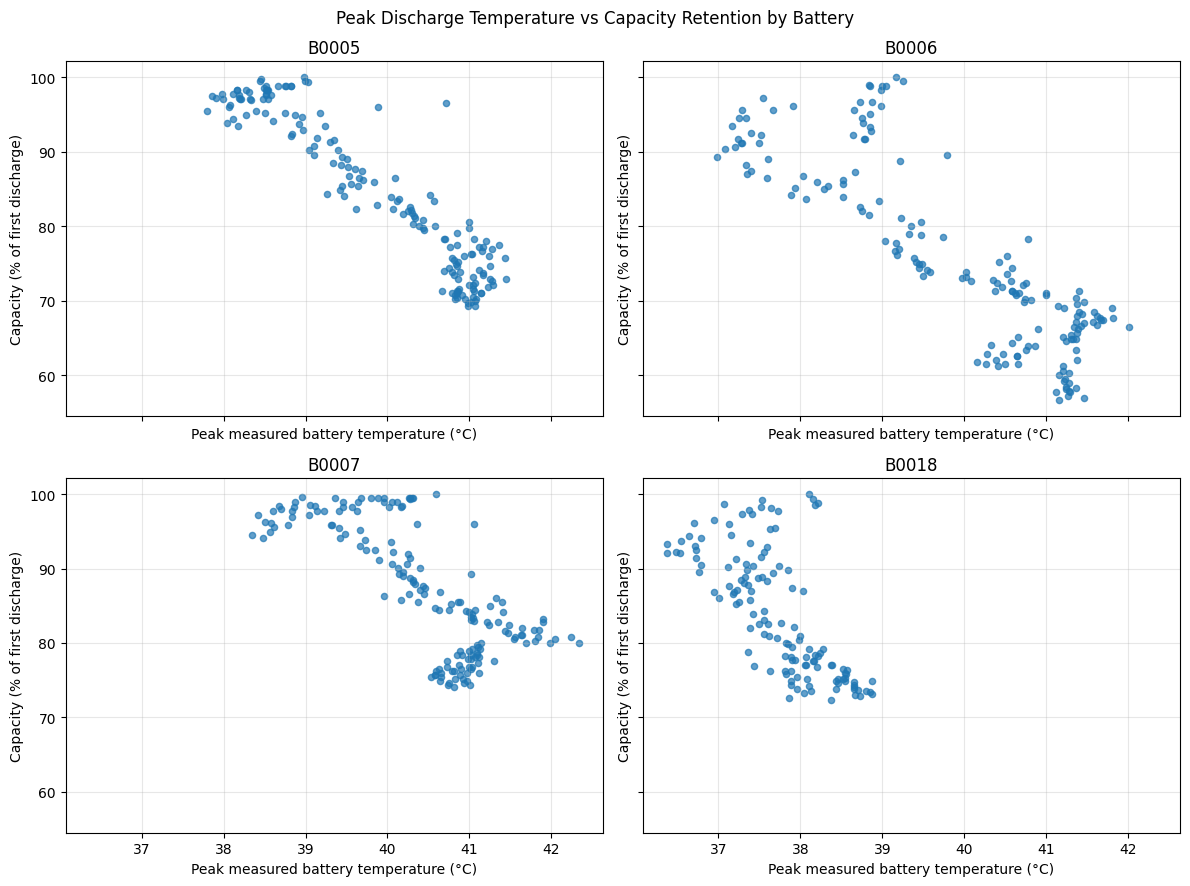

In [19]:
# @title
temperature_capacity = discharge_table.sort_values(
    ["battery", "discharge_number"]
).copy()

first_capacity = temperature_capacity.groupby("battery")[
    "capacity_ah"
].transform("first")

temperature_capacity["capacity_pct_of_first"] = (
    100 * temperature_capacity["capacity_ah"] / first_capacity
)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)

for ax, battery in zip(axes.flat, BATTERIES):
    group = temperature_capacity[
        temperature_capacity["battery"] == battery
    ]

    ax.scatter(
        group["max_temperature_c"],
        group["capacity_pct_of_first"],
        alpha=0.7,
        s=20,
    )
    ax.set_title(battery)
    ax.set_xlabel("Peak measured battery temperature (°C)")
    ax.set_ylabel("Capacity (% of first discharge)")
    ax.grid(True, alpha=0.3)

fig.suptitle("Peak Discharge Temperature vs Capacity Retention by Battery")
plt.tight_layout()
plt.show()

## Interpreting Peak Discharge Temperature and Capacity Retention

The scatter plots show a **general negative association**: within each battery, higher peak discharge temperatures often occur alongside lower capacity retention. That’s a pattern in these measurements, not proof that temperature caused the capacity loss.

| Battery | Interpretation |
|---|---|
| **B0005** | The clearest downward pattern: higher peak temperatures generally coincide with lower capacity retention. |
| **B0006** | The overall pattern is downward, but there is more scatter and several clusters. Temperature alone doesn’t explain the capacity changes. |
| **B0007** | The overall pattern is also downward, with noticeable clusters and exceptions. |
| **B0018** | Capacity retention declines even though its peak temperatures are generally lower than the other batteries. That suggests temperature alone cannot explain the fade. |

The plot uses each battery’s own first discharge as 100% capacity. Also, the cells have different discharge cut-off voltages, so compare the pattern within each battery rather than ranking them directly by capacity or temperature. [FY08Q4 test conditions](https://www.mdpi.com/2227-9717/11/3/678)

One limitation: the scatter plot does not show the order of the cycles. Each dot is a discharge, positioned by its peak temperature. For the next step, we should color the dots by discharge number so we can see how the relationship develops over time.

## Show Cycle Order in the Temperature–Capacity Scatter Plot

/tmp/ipykernel_658/2283911261.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


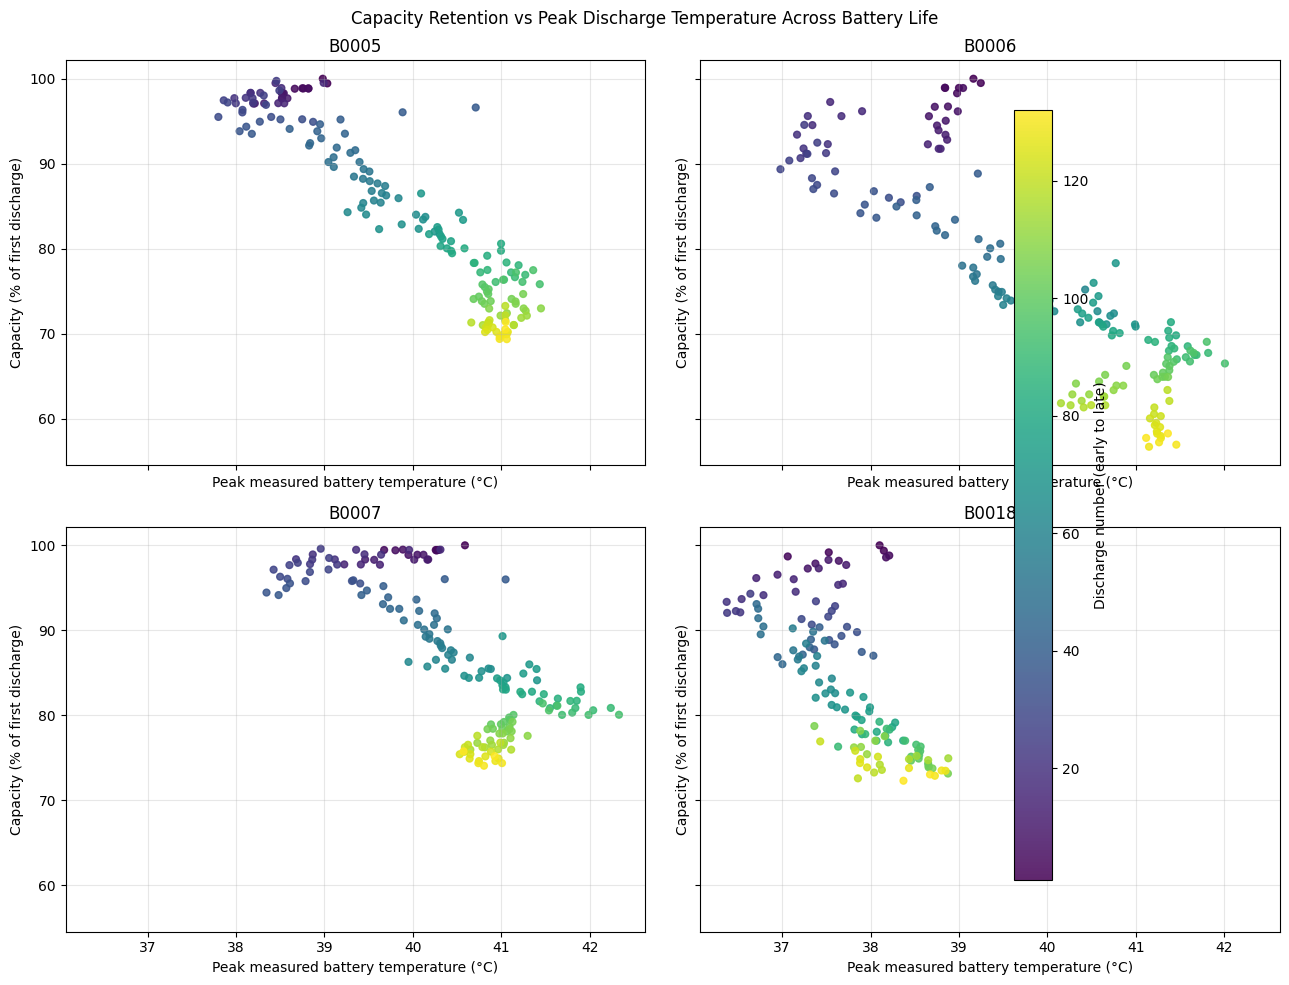

In [20]:
# @title
colored_data = discharge_table.sort_values(
    ["battery", "discharge_number"]
).copy()

first_capacity = colored_data.groupby("battery")["capacity_ah"].transform("first")
colored_data["capacity_pct_of_first"] = (
    100 * colored_data["capacity_ah"] / first_capacity
)

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
last_scatter = None

for ax, battery in zip(axes.flat, BATTERIES):
    group = colored_data[colored_data["battery"] == battery]

    last_scatter = ax.scatter(
        group["max_temperature_c"],
        group["capacity_pct_of_first"],
        c=group["discharge_number"],
        cmap="viridis",
        s=24,
        alpha=0.85,
    )

    ax.set_title(battery)
    ax.set_xlabel("Peak measured battery temperature (°C)")
    ax.set_ylabel("Capacity (% of first discharge)")
    ax.grid(True, alpha=0.3)

fig.suptitle("Capacity Retention vs Peak Discharge Temperature Across Battery Life")
colorbar = fig.colorbar(last_scatter, ax=axes.ravel().tolist(), pad=0.02)
colorbar.set_label("Discharge number (early to late)")

plt.tight_layout()
plt.show()